# Figuras dos resultados — calibração nacional do CROPGRO-Soybean por GMR

Compilação, por capítulo, de todas as figuras possíveis com os resultados disponíveis. Depois escolhemos as melhores
para cada artigo (ASD agronômico; MLCSE computacional). Regras: sem tabelas — dados tabulares viram heatmaps com
**classificação** (cor = classe, número escrito na célula); mapas sobre os estados do Brasil; paleta validada
(categórica em ordem fixa, sequencial azul, divergente azul↔vermelho, status reservado às classificações).
As figuras são salvas em `resultados/figuras/` (PNG e PDF). Resultados ainda em execução (cadeias v7) são usados
quando existirem; senão, a versão mais recente concluída.

**Capítulos:** 1 Visão geral · 2 Dados meteorológicos · 3 Solos · 4 Cultura da soja · 5 Literatura e observações ·
6 Sensibilidade · 7 Replicação de Battisti & Sentelhas (2019) · 8 Emulador · 9 Calibração bayesiana · 10 Satélite e inferência amortizada

In [1]:
import sys, warnings, json
from pathlib import Path
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl, emcee
import figuras as fg
fg.estilo()
CAT, SEQ, ST = fg.CAT, fg.SEQ, fg.STATUS
DE = RAIZ / "resultados" / "emulador_fenologia"
print("pasta de figuras:", fg.DIR_FIG)

pasta de figuras: /Users/coted-sh/Python/DSSAT/calibracao_mg/resultados/figuras


## 1 Visão geral

**Figura 1.1 — Fluxo do projeto.** Das bases de dados (clima, solo, área de soja, literatura, satélite, IBGE) ao
modelo, ao emulador, à calibração bayesiana e aos produtos (coeficientes por GMR, GMR efetivo, lacuna de
produtividade). Serve de figura de abertura nos dois artigos.

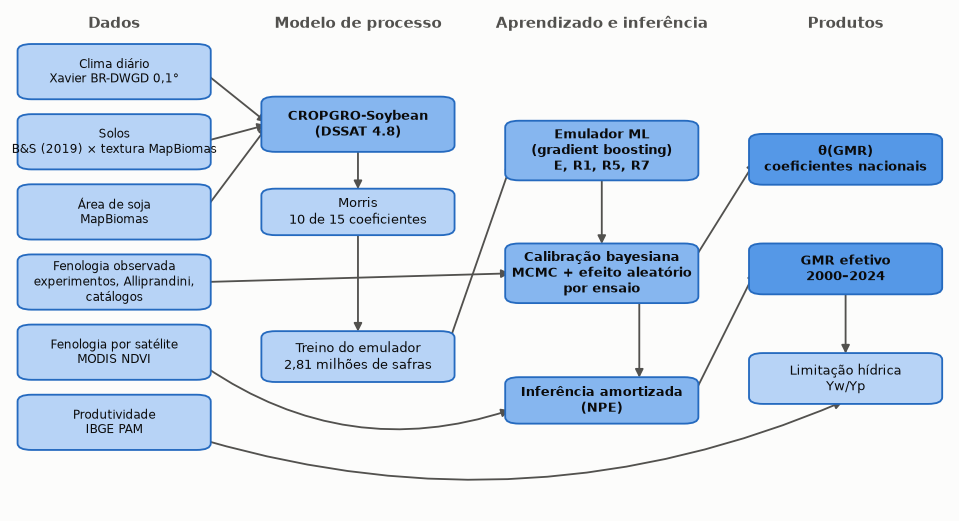

In [2]:
fig, ax = plt.subplots(figsize=(11, 5.9)); fg.tela(ax); ax.set_ylim(-0.1, 1.04)
c1, c2, c3, c4 = 0.11, 0.37, 0.63, 0.89
dados = ["Clima diário\nXavier BR-DWGD 0,1°", "Solos\nB&S (2019) × textura MapBiomas", "Área de soja\nMapBiomas",
         "Fenologia observada\nexperimentos, Alliprandini,\ncatálogos", "Fenologia por satélite\nMODIS NDVI", "Produtividade\nIBGE PAM"]
ys = np.linspace(0.9, 0.1, len(dados))
for y, t in zip(ys, dados):
    fg.caixa(ax, c1, y, t, w=0.19, h=0.11, fs=7.8)
fg.caixa(ax, c2, 0.78, "CROPGRO-Soybean\n(DSSAT 4.8)", cor=SEQ[3], w=0.19, h=0.11, peso="bold")
fg.caixa(ax, c2, 0.58, "Morris\n10 de 15 coeficientes", w=0.19, h=0.09)
fg.caixa(ax, c2, 0.25, "Treino do emulador\n2,81 milhões de safras", w=0.19, h=0.1)
fg.caixa(ax, c3, 0.72, "Emulador ML\n(gradient boosting)\nE, R1, R5, R7", cor=SEQ[3], w=0.19, h=0.12, peso="bold")
fg.caixa(ax, c3, 0.44, "Calibração bayesiana\nMCMC + efeito aleatório\npor ensaio", cor=SEQ[3], w=0.19, h=0.12, peso="bold")
fg.caixa(ax, c3, 0.15, "Inferência amortizada\n(NPE)", cor=SEQ[3], w=0.19, h=0.09, peso="bold")
fg.caixa(ax, c4, 0.7, "θ(GMR)\ncoeficientes nacionais", cor=SEQ[5], w=0.19, h=0.1, peso="bold")
fg.caixa(ax, c4, 0.45, "GMR efetivo\n2000–2024", cor=SEQ[5], w=0.19, h=0.1, peso="bold")
fg.caixa(ax, c4, 0.2, "Limitação hídrica\nYw/Yp", cor=SEQ[1], w=0.19, h=0.1)
for y in ys[:3]:
    fg.seta(ax, c1 + 0.095, y, c2 - 0.095, 0.78)
fg.seta(ax, c2, 0.725, c2, 0.625); fg.seta(ax, c2, 0.535, c2, 0.3)
fg.seta(ax, c2 + 0.095, 0.27, c3 - 0.095, 0.7); fg.seta(ax, c3, 0.66, c3, 0.5)
fg.seta(ax, c1 + 0.095, ys[3], c3 - 0.095, 0.44); fg.seta(ax, c1 + 0.095, ys[4] - 0.03, c3 - 0.095, 0.13, curva=0.25)
fg.seta(ax, c3 + 0.095, 0.46, c4 - 0.095, 0.7); fg.seta(ax, c3 + 0.04, 0.38, c3 + 0.04, 0.195)
fg.seta(ax, c3 + 0.095, 0.15, c4 - 0.095, 0.45); fg.seta(ax, c1 + 0.095, ys[5] - 0.04, c4, 0.15, curva=0.18)
fg.seta(ax, c4, 0.4, c4, 0.25)
for x, t in zip([c1, c2, c3, c4], ["Dados", "Modelo de processo", "Aprendizado e inferência", "Produtos"]):
    ax.text(x, 1.0, t, ha="center", fontsize=10, weight="bold", color=fg.TEXTO_2)
fg.salvar(fig, "1_1_fluxo_projeto")

**Figura 1.2 — Evolução da calibração (v1 → v7).** Cada versão corrigiu um problema diagnosticado na anterior; a cor
indica o estado da convergência entre cadeias independentes (pior R-hat dos parâmetros de fenologia). Mostra ao leitor
do artigo computacional como os diagnósticos orientaram o desenho (dado inconsistente → faixas → identificabilidade →
R5 → R1PPO → efeito aleatório).

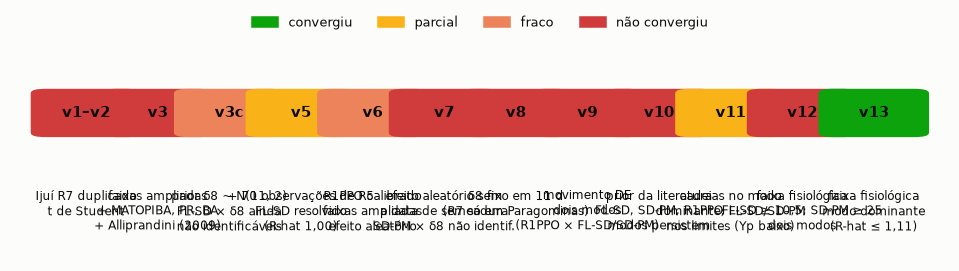

In [3]:
versoes = [("v1–v2", "Ijuí R7 duplicado\nt de Student", "crítico"),
           ("v3", "faixas ampliadas\n+ MATOPIBA, PR, BA\n+ Alliprandini (2009)", "crítico"),
           ("v3c", "prior δ8 ~ N(11, 2)\nFL-SD × δ8 ainda\nnão identificáveis", "sério"),
           ("v5", "+ 70 observações de R5\nFL-SD resolvido\n(R-hat 1,00)", "atenção"),
           ("v6", "R1PPO calibrado\nfaixas ampliadas\nefeito aleatório", "sério"),
           ("v7", "efeito aleatório sem\na data de semeadura\nSD-PM × δ8 não identif.", "crítico"),
           ("v8", "δ8 fixo em 11 d\n(R7 só em Paragominas)", "crítico"),
           ("v9", "movimento DE\ndois modos\n(R1PPO × FL-SD/SD-PM)", "crítico"),
           ("v10", "prior da literatura\nFL-SD, SD-PM, R1PPO\nmodos persistem", "crítico"),
           ("v11", "cadeias no modo\ndominante; FL-SD/SD-PM\nnos limites (Yp baixo)", "atenção"),
           ("v12", "faixa fisiológica\nFL-SD ≥ 10,5; SD-PM ≥ 25\ndois modos", "crítico"),
           ("v13", "faixa fisiológica\nmodo dominante\n(R-hat ≤ 1,11)", "bom")]
fig, ax = plt.subplots(figsize=(11, 2.8)); fg.tela(ax)
xs = np.linspace(0.08, 0.92, len(versoes))
for x, (v, t, s) in zip(xs, versoes):
    fg.caixa(ax, x, 0.62, v, cor=ST[s], borda=ST[s], w=0.1, h=0.18, fs=10, peso="bold")
    ax.text(x, 0.3, t, ha="center", va="top", fontsize=7.6, color=fg.TEXTO)
for a, b in zip(xs[:-1], xs[1:]):
    fg.seta(ax, a + 0.055, 0.62, b - 0.055, 0.62)
alcas = [mpl.patches.Patch(color=c, label=l) for l, c in [("convergiu", ST["bom"]), ("parcial", ST["atenção"]),
         ("fraco", ST["sério"]), ("não convergiu", ST["crítico"])]]
ax.legend(handles=alcas, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.08))
fg.salvar(fig, "1_2_versoes_calibracao")

**Figura 1.3 — Estrutura estatística da calibração.** Os coeficientes variam linearmente com o GMR; cada tipo de
observação entra com seu modelo de erro; nos experimentos, o intercepto aleatório por estudo × local × safra × estádio
absorve diferenças de definição de estádio sem esconder a resposta à época de semeadura.

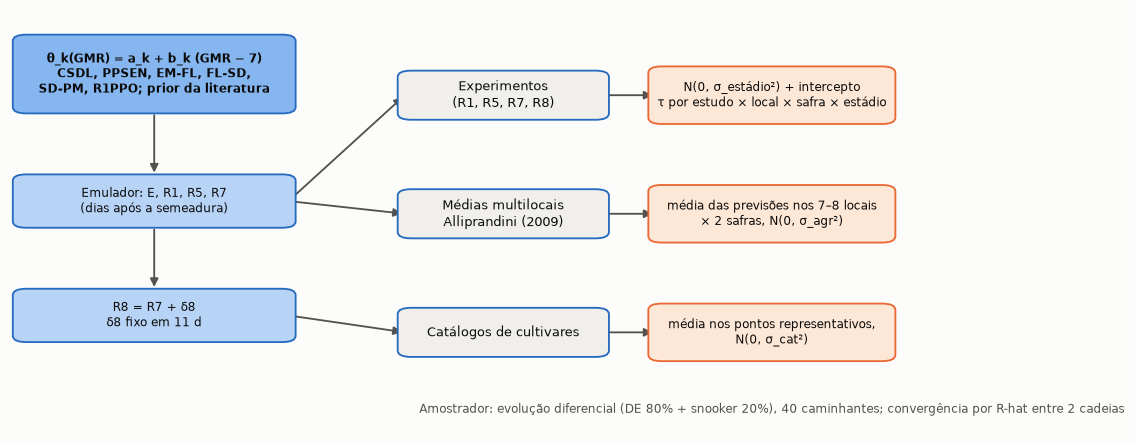

In [4]:
fig, ax = plt.subplots(figsize=(10.5, 5)); fg.tela(ax)
fg.caixa(ax, 0.16, 0.85, "θ_k(GMR) = a_k + b_k (GMR − 7)\nCSDL, PPSEN, EM-FL, FL-SD,\nSD-PM, R1PPO; prior da literatura", cor=SEQ[3], w=0.3, h=0.17, fs=8, peso="bold")
fg.caixa(ax, 0.16, 0.55, "Emulador: E, R1, R5, R7\n(dias após a semeadura)", w=0.3, h=0.11, fs=8)
fg.caixa(ax, 0.16, 0.28, "R8 = R7 + δ8\nδ8 fixo em 11 d", w=0.3, h=0.11, fs=8)
obs = [("Experimentos\n(R1, R5, R7, R8)", "N(0, σ_estádio²) + intercepto\nτ por estudo × local × safra × estádio"),
       ("Médias multilocais\nAlliprandini (2009)", "média das previsões nos 7–8 locais\n× 2 safras, N(0, σ_agr²)"),
       ("Catálogos de cultivares", "média nos pontos representativos,\nN(0, σ_cat²)")]
for i, (o, e) in enumerate(obs):
    y = 0.8 - 0.28 * i
    fg.caixa(ax, 0.55, y, o, cor=fg.CINZA_MEIO, w=0.22, h=0.1)
    fg.caixa(ax, 0.85, y, e, cor="#fde7d6", borda=CAT[1], w=0.26, h=0.12, fs=7.6)
    fg.seta(ax, 0.66, y, 0.72, y)
    fg.seta(ax, 0.31, 0.55 if i < 2 else 0.28, 0.44, y)
fg.seta(ax, 0.16, 0.76, 0.16, 0.61); fg.seta(ax, 0.16, 0.49, 0.16, 0.34)
ax.text(0.85, 0.05, "Amostrador: evolução diferencial (DE 80% + snooker 20%), 40 caminhantes; convergência por R-hat entre 2 cadeias",
        ha="center", fontsize=7.8, color=fg.TEXTO_2)
fg.salvar(fig, "1_3_estrutura_estatistica")

## 2 Dados meteorológicos

In [5]:
# resumo climático dos 462 pontos (cache): safra = out–mar; tendência de Tmed por década (1981–2024)
arq = fg.DIR_FIG / "cache_clima_pontos.parquet"
pts = pd.read_csv(RAIZ / "dados/processados/pontos_bs2019_digitalizados.csv")
if arq.exists():
    clima = pd.read_parquet(arq)
else:
    linhas, mensal = [], []
    for r in pts.itertuples():
        f = RAIZ / f"dados/brutos/xavier/xavier_no_{r.lon:+.2f}_{r.lat:+.2f}_1980_2025.csv.gz"
        if not f.exists():
            continue
        c = pd.read_csv(f, index_col=0, parse_dates=True)
        c["tmed"] = (c.Tmax + c.Tmin) / 2
        c["safra"] = c.index.year - (c.index.month < 7)
        s = c[c.index.month.isin([10, 11, 12, 1, 2, 3]) & c.safra.between(1981, 2024)]
        por = s.groupby("safra").agg(tmed=("tmed", "mean"), pr=("pr", "sum"), rs=("Rs", "mean"), et=("ET", "sum"))
        tend = np.polyfit(por.index, por.tmed, 1)[0] * 10
        linhas.append(dict(lon=r.lon, lat=r.lat, elev=r.elev, tmed=por.tmed.mean(), pr=por.pr.mean(), rs=por.rs.mean(),
                           et=por.et.mean(), deficit=(por.et - por.pr).mean(), cv_pr=por.pr.std() / por.pr.mean(), tend_tmed=tend,
                           tend_pr=np.polyfit(por.index, por.pr, 1)[0] * 10))
        n = c[(c.index.year >= 1991) & (c.index.year <= 2020)]
        m = n.groupby(n.index.month).agg(tmed=("tmed", "mean"), pr=("pr", "sum"))
        m["pr"] /= 30; m["lon"], m["lat"] = r.lon, r.lat
        mensal.append(m.reset_index(names="mes"))
    clima = pd.DataFrame(linhas); clima.to_parquet(arq)
    pd.concat(mensal).to_parquet(fg.DIR_FIG / "cache_clima_mensal.parquet")
mensal = pd.read_parquet(fg.DIR_FIG / "cache_clima_mensal.parquet")
soja = pd.read_csv(RAIZ / "dados/processados/fracoes_solo_mapbiomas_soja2016.csv")[["lon", "lat", "soja_ha"]]
clima = clima.merge(soja, on=["lon", "lat"], how="left")
print(len(clima), "pontos")

462 pontos


**Figura 2.1 — Clima da safra (out–mar, média 1981–2024) nos 462 pontos.** Temperatura média, chuva acumulada,
radiação solar e balanço (ET − chuva). Mostra os gradientes que a calibração precisa cobrir: o Sul mais frio e o
MATOPIBA quente e com estação chuvosa curta.

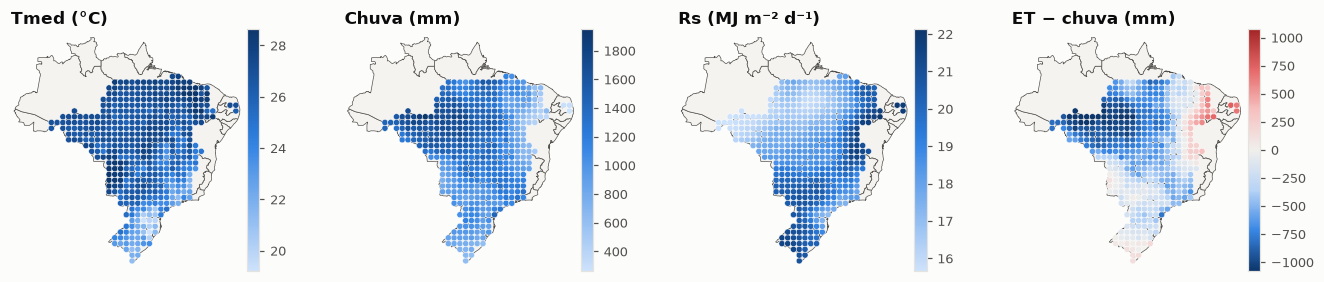

In [6]:
fig, axs = plt.subplots(1, 4, figsize=(15, 4.4))
cfg = [("tmed", "Tmed (°C)", fg.CMAP_SEQ, None), ("pr", "Chuva (mm)", fg.CMAP_SEQ, None), ("rs", "Rs (MJ m⁻² d⁻¹)", fg.CMAP_SEQ, None),
       ("deficit", "ET − chuva (mm)", fg.CMAP_DIV, "centro")]
for ax, (v, tit, cm, centro) in zip(axs, cfg):
    fg.mapa_base(ax)
    kw = {}
    if centro:
        lim = np.nanpercentile(np.abs(clima[v]), 98); kw = dict(vmin=-lim, vmax=lim)
    sc = ax.scatter(clima.lon, clima.lat, c=clima[v], cmap=cm, s=16, edgecolor="white", linewidth=0.3, zorder=3, **kw)
    ax.set_title(tit); plt.colorbar(sc, ax=ax, shrink=0.65, pad=0.01)
fg.salvar(fig, "2_1_clima_safra")

**Figura 2.2 — Tendência climática na safra (1981–2024, por década).** Aquecimento da temperatura média e variação
da chuva. Relevante para a discussão do encurtamento do ciclo observado por satélite: parte dele pode ser efeito da
temperatura, e não só da troca de cultivares — o emulador separa os dois.

aquecimento médio: 0.259 °C/década


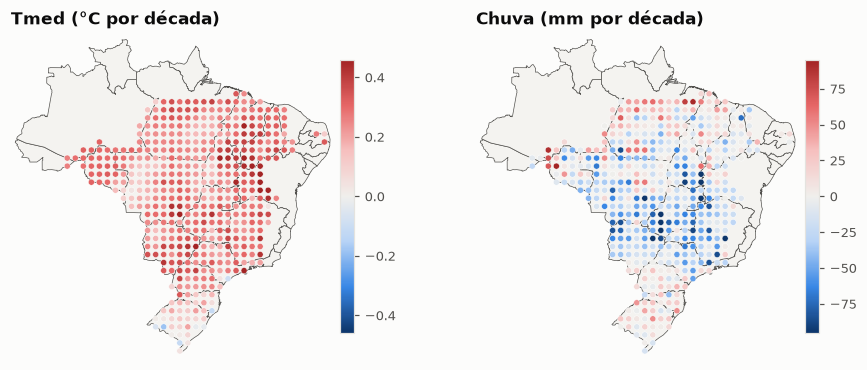

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, (v, tit) in zip(axs, [("tend_tmed", "Tmed (°C por década)"), ("tend_pr", "Chuva (mm por década)")]):
    fg.mapa_base(ax)
    lim = np.nanpercentile(np.abs(clima[v]), 98)
    sc = ax.scatter(clima.lon, clima.lat, c=clima[v], cmap=fg.CMAP_DIV, vmin=-lim, vmax=lim, s=16, edgecolor="white", linewidth=0.3, zorder=3)
    ax.set_title(tit); plt.colorbar(sc, ax=ax, shrink=0.7, pad=0.01)
fg.salvar(fig, "2_2_tendencia_clima")
print("aquecimento médio:", clima.tend_tmed.mean().round(3), "°C/década")

**Figura 2.3 — Regime mensal por faixa de latitude (1991–2020).** Temperatura e chuva em painéis separados (um eixo
por gráfico). A janela de semeadura de cada região acompanha o início das chuvas, o que explica a dispersão de datas
que o emulador precisou cobrir (10/set a 28/fev).

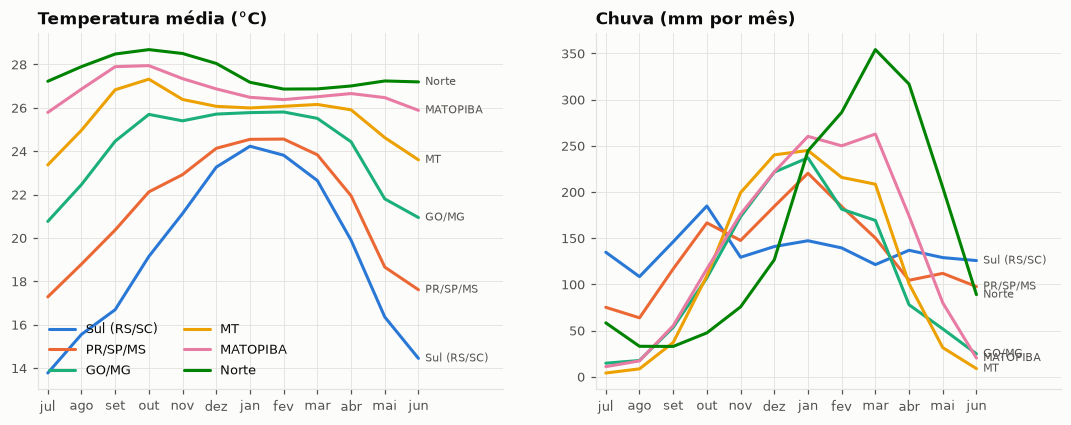

In [8]:
faixas = [(-35, -27, "Sul (RS/SC)"), (-27, -22, "PR/SP/MS"), (-22, -17, "GO/MG"), (-17, -12, "MT"), (-12, -5, "MATOPIBA"), (-5, 6, "Norte")]
ordem = [7, 8, 9, 10, 11, 12, 1, 2, 3, 4, 5, 6]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for k, (a, b, nome) in enumerate(faixas):
    m = mensal[(mensal.lat > a) & (mensal.lat <= b)].groupby("mes")[["tmed", "pr"]].mean().loc[ordem]
    for ax, v in zip(axs, ["tmed", "pr"]):
        ax.plot(range(12), m[v].values, color=CAT[k], label=nome)
        ax.text(11.2, m[v].values[-1], nome, fontsize=7.5, color=fg.TEXTO_2, va="center")
for ax, t in zip(axs, ["Temperatura média (°C)", "Chuva (mm por mês)"]):
    ax.set_xticks(range(12), ["jul", "ago", "set", "out", "nov", "dez", "jan", "fev", "mar", "abr", "mai", "jun"]); ax.set_title(t)
    ax.set_xlim(-0.3, 13.5)
axs[0].legend(loc="lower left", ncol=2)
fg.salvar(fig, "2_3_regime_mensal")

**Figura 2.4 — Fotoperíodo ao longo da safra em três latitudes.** Comprimento do dia com crepúsculo civil (como no
CROPGRO). A amplitude cresce com a latitude: no Sul a semeadura de setembro expõe a planta a dias de até ~14,5 h,
o que torna a resposta à época — e o R1PPO — decisiva.

/Users/coted-sh/Python/DSSAT/calibracao_mg/.venv/lib/python3.11/site-packages/DSSATTools/__init__.py:105: DeprecationWarning: DSSATTools version 3.0.0 is a major upgrade and will not be backwards compatible with previous versions. If you are running code that was developed  using a previous DSSATTools version, then install DSSATTools version 2.1.6
  warnings.warn(


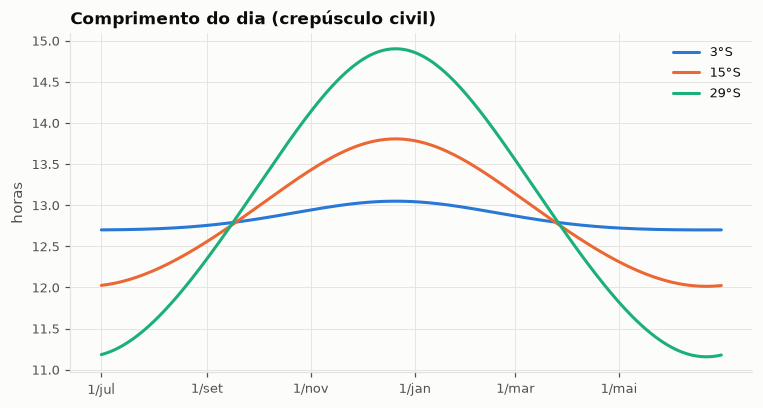

In [9]:
import emulador_fenologia as ef
doy = np.arange(1, 366); fig, ax = plt.subplots(figsize=(8, 4))
for k, la in enumerate([-3, -15, -29]):
    fp = ef.fotoperiodo(la, doy); sh = np.r_[doy[doy >= 182], doy[doy < 182]]
    ax.plot(range(365), ef.fotoperiodo(la, sh), color=CAT[k], label=f"{abs(la)}°S")
ax.set_xticks([0, 62, 123, 184, 243, 304], ["1/jul", "1/set", "1/nov", "1/jan", "1/mar", "1/mai"])
ax.set_ylabel("horas"); ax.set_title("Comprimento do dia (crepúsculo civil)"); ax.legend()
fg.salvar(fig, "2_4_fotoperiodo")

## 3 Solos

**Figura 3.1 — Textura dominante dos solos sob soja (MapBiomas, 2016) e teor médio de argila (0–100 cm).** A classe
dominante define o peso dos três perfis de Battisti & Sentelhas (2019) em cada ponto; a argila mostra o contraste
entre os solos arenosos do MATOPIBA/Arenito e os argilosos do Planalto.

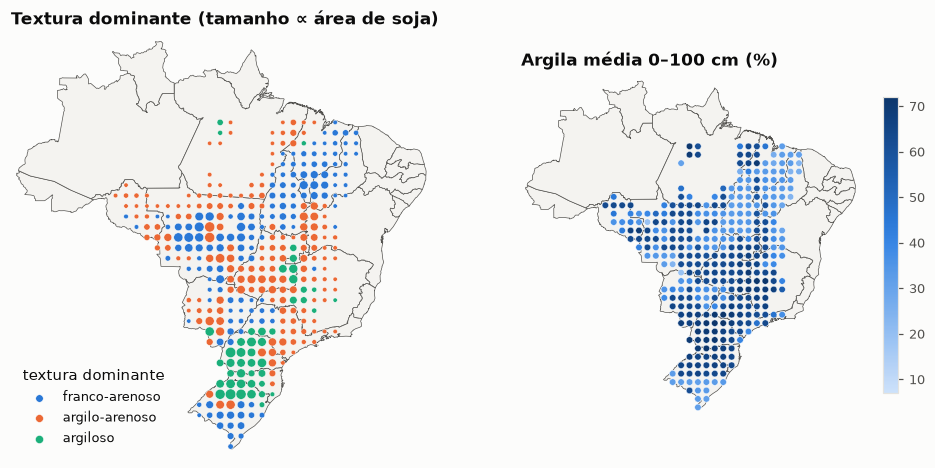

In [10]:
fr = pd.read_csv(RAIZ / "dados/processados/fracoes_solo_mapbiomas_soja2016.csv")
pf = pd.read_csv(RAIZ / "dados/processados/perfis_solo_mapbiomas_soja2016.csv")
pf["argila"] = pf[[c for c in pf if c.startswith("clay_")]].mean(axis=1)
classes = ["f_francoarenoso", "f_argiloarenoso", "f_argiloso"]; nomes = ["franco-arenoso", "argilo-arenoso", "argiloso"]
fr = fr[fr.soja_ha > 0].copy(); fr["dom"] = fr[classes].values.argmax(axis=1)
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
fg.mapa_base(axs[0])
for k, n in enumerate(nomes):
    s = fr[fr.dom == k]
    axs[0].scatter(s.lon, s.lat, color=CAT[k], s=8 + 40 * np.sqrt(s.soja_ha / fr.soja_ha.max()), edgecolor="white", linewidth=0.3, zorder=3, label=n)
axs[0].legend(loc="lower left", title="textura dominante"); axs[0].set_title("Textura dominante (tamanho ∝ área de soja)")
fg.mapa_base(axs[1])
sc = axs[1].scatter(pf.lon, pf.lat, c=pf.argila, cmap=fg.CMAP_SEQ, s=18, edgecolor="white", linewidth=0.3, zorder=3)
axs[1].set_title("Argila média 0–100 cm (%)"); plt.colorbar(sc, ax=axs[1], shrink=0.7)
fg.salvar(fig, "3_1_solos")

## 4 Cultura da soja

**Figura 4.1 — Área de soja (MapBiomas, 2016) na grade de 1°.** Fração da célula ocupada pela soja; é a máscara que
define onde a calibração e o satélite importam.

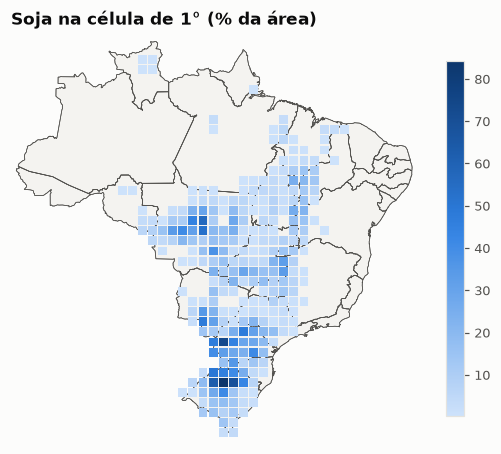

In [11]:
g = pd.read_csv(RAIZ / "dados/processados/grade1grau_frac_soja_2016.csv"); g = g[g.frac_soja > 0.002]
fig, ax = plt.subplots(figsize=(6, 6)); fg.mapa_base(ax)
sc = ax.scatter(g.lon, g.lat, c=100 * g.frac_soja, cmap=fg.CMAP_SEQ, s=34, marker="s", linewidth=0, zorder=2)
fg.mapa_base(ax, fundo=False); ax.set_title("Soja na célula de 1° (% da área)"); plt.colorbar(sc, ax=ax, shrink=0.7)
fg.salvar(fig, "4_1_area_soja")

**Figura 4.2 — Produtividade municipal (IBGE PAM, média 2015–2024).** Base do capítulo de lacuna de produtividade:
a calibração fornecerá a produtividade limitada pela água em cada município para comparar com estes valores.

2037 municípios com > 500 ha


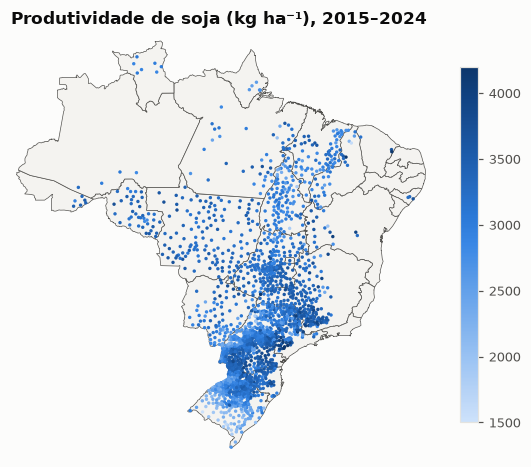

In [12]:
ib = pd.read_csv(RAIZ / "dados/brutos/ibge/sidra_1612_soja_municipios_1980_2024.csv")
cen = pd.read_csv(RAIZ / "dados/processados/centroides_municipios.csv")
rec = ib[ib.ano.between(2015, 2024)].groupby("cod_municipio").agg(rend=("rendimento_kg_ha", "mean"), area=("area_colhida_ha", "mean")).reset_index()
rec = rec.merge(cen, left_on="cod_municipio", right_on="cod"); rec = rec[rec.area > 500]
fig, ax = plt.subplots(figsize=(6.2, 6)); fg.mapa_base(ax)
sc = ax.scatter(rec.lon, rec.lat, c=rec.rend, cmap=fg.CMAP_SEQ, s=5, vmin=1500, vmax=4200, linewidth=0, zorder=3)
ax.set_title("Produtividade de soja (kg ha⁻¹), 2015–2024"); plt.colorbar(sc, ax=ax, shrink=0.7)
fg.salvar(fig, "4_2_produtividade_ibge")
print(len(rec), "municípios com > 500 ha")

**Figura 4.3 — Evolução da produtividade por faixa de latitude (IBGE, 1980–2024).** Média ponderada pela área
colhida. Destaca as quebras por seca (ex.: 2004/05, 2011/12 e 2021/22 no Sul) que a calibração da produtividade
deverá reproduzir.

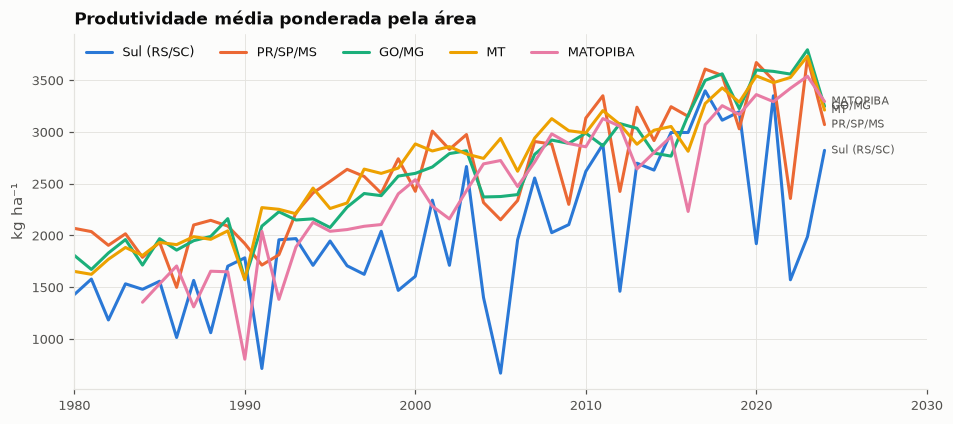

In [13]:
d = ib.merge(cen, left_on="cod_municipio", right_on="cod").dropna(subset=["rendimento_kg_ha", "area_colhida_ha"])
fig, ax = plt.subplots(figsize=(10, 4.2))
for k, (a, b, nome) in enumerate(faixas[:5]):
    s = d[(d.lat > a) & (d.lat <= b)]
    t = s.groupby("ano").apply(lambda x: np.average(x.rendimento_kg_ha, weights=x.area_colhida_ha))
    t = t[s.groupby("ano").area_colhida_ha.sum() > 20000]
    ax.plot(t.index, t.values, color=CAT[k], label=nome); ax.text(t.index[-1] + 0.4, t.values[-1], nome, fontsize=7.5, color=fg.TEXTO_2, va="center")
ax.set_ylabel("kg ha⁻¹"); ax.set_title("Produtividade média ponderada pela área"); ax.set_xlim(1980, 2030); ax.legend(ncol=5, loc="upper left")
fg.salvar(fig, "4_3_produtividade_serie")

## 5 Literatura e observações

**Figura 5.1 — Onde estão as observações.** Experimentos de campo, os 15 locais de Alliprandini et al. (2009), os
pontos representativos dos catálogos e os 224 pontos com fenologia de satélite. Mostra a cobertura de latitude que
torna a calibração nacional.

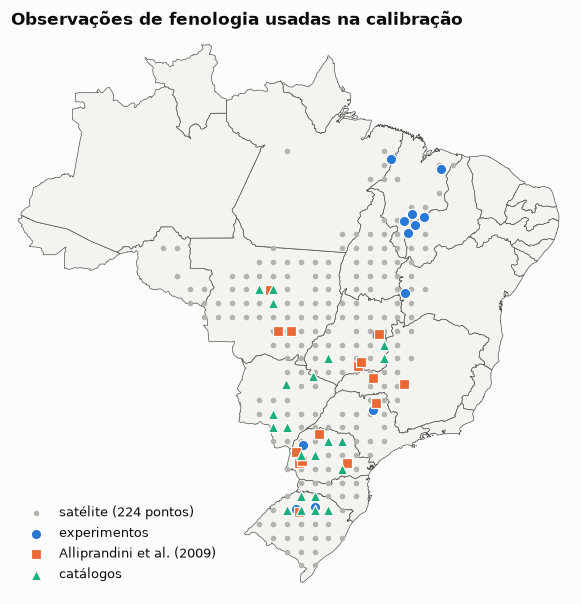

In [14]:
L = pd.read_csv(DE / "locais.csv", index_col="idx_local")
o = pd.read_csv(DE / "observacoes_fenologia.csv")
sat = pd.read_csv(RAIZ / "resultados/fenologia_satelite/fenologia_modis_pontos.csv").dropna(subset=["sos_p50"])[["lon", "lat"]].drop_duplicates()
fig, ax = plt.subplots(figsize=(6.6, 6.6)); fg.mapa_base(ax)
ax.scatter(sat.lon, sat.lat, s=7, color="#b5b3ad", zorder=2, label="satélite (224 pontos)")
for k, (tipo, nome, mk) in enumerate([("experimento", "experimentos", "o"), ("agregado", "Alliprandini et al. (2009)", "s"), ("catalogo", "catálogos", "^")]):
    ii = o[o.tipo == tipo].idx_local.unique()
    ax.scatter(L.loc[ii, "lon"], L.loc[ii, "lat"], marker=mk, s=46, color=CAT[k], edgecolor="white", linewidth=0.8, zorder=4, label=nome)
ax.legend(loc="lower left"); ax.set_title("Observações de fenologia usadas na calibração")
fg.salvar(fig, "5_1_mapa_observacoes")

**Figura 5.2 — Cobertura das observações por região × GMR.** Número de registros (experimentos + médias de
Alliprandini + catálogos); a classe indica se a combinação está bem representada. As lacunas (células vermelhas)
são onde a calibração depende de extrapolação.

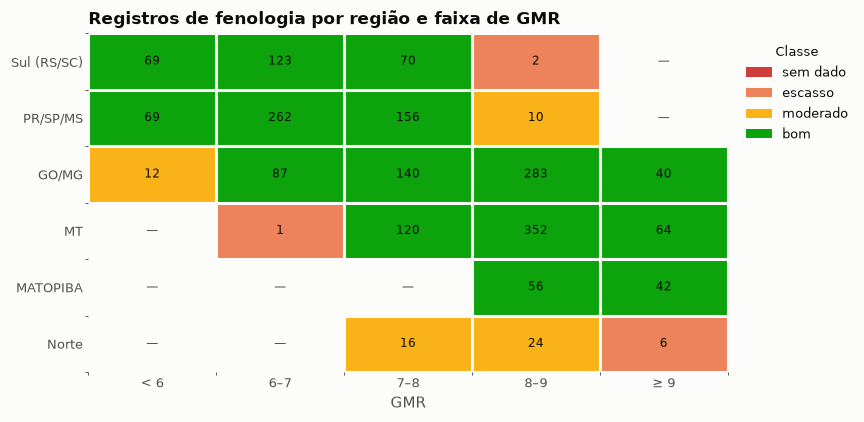

In [15]:
reg = lambda la: next(n for a, b, n in faixas if a < la <= b)
oo = o.drop_duplicates(subset=["tipo", "fonte", "idx_local", "data_semeadura", "gmr", "estadio", "id_registro"]).copy()
oo["regiao"] = oo.lat.map(reg); oo["faixa_gmr"] = pd.cut(oo.gmr, [4.7, 6, 7, 8, 9, 9.6], labels=["< 6", "6–7", "7–8", "8–9", "≥ 9"])
cont = oo.groupby(["regiao", "faixa_gmr"]).size().unstack().reindex([n for *_, n in faixas])
fig, ax = plt.subplots(figsize=(7.5, 4))
fg.heatmap_classes(ax, cont.values, cont.index, cont.columns, [-0.5, 0.5, 10, 30, 1e9], ["sem dado", "escasso", "moderado", "bom"],
                   [ST["crítico"], ST["sério"], ST["atenção"], ST["bom"]], fmt="{:.0f}")
ax.set_title("Registros de fenologia por região e faixa de GMR"); ax.set_xlabel("GMR")
fg.salvar(fig, "5_2_cobertura_regiao_gmr")

**Figura 5.3 — Coeficientes publicados para cultivares brasileiras.** Valor de cada coeficiente posicionado na faixa
usada na calibração (0 = mínimo, 1 = máximo); o número na célula é o valor original. Mostra a dispersão entre
calibrações independentes — por exemplo, SD-PM de 25 a 38 — que motivou calibrar θ como função do GMR.

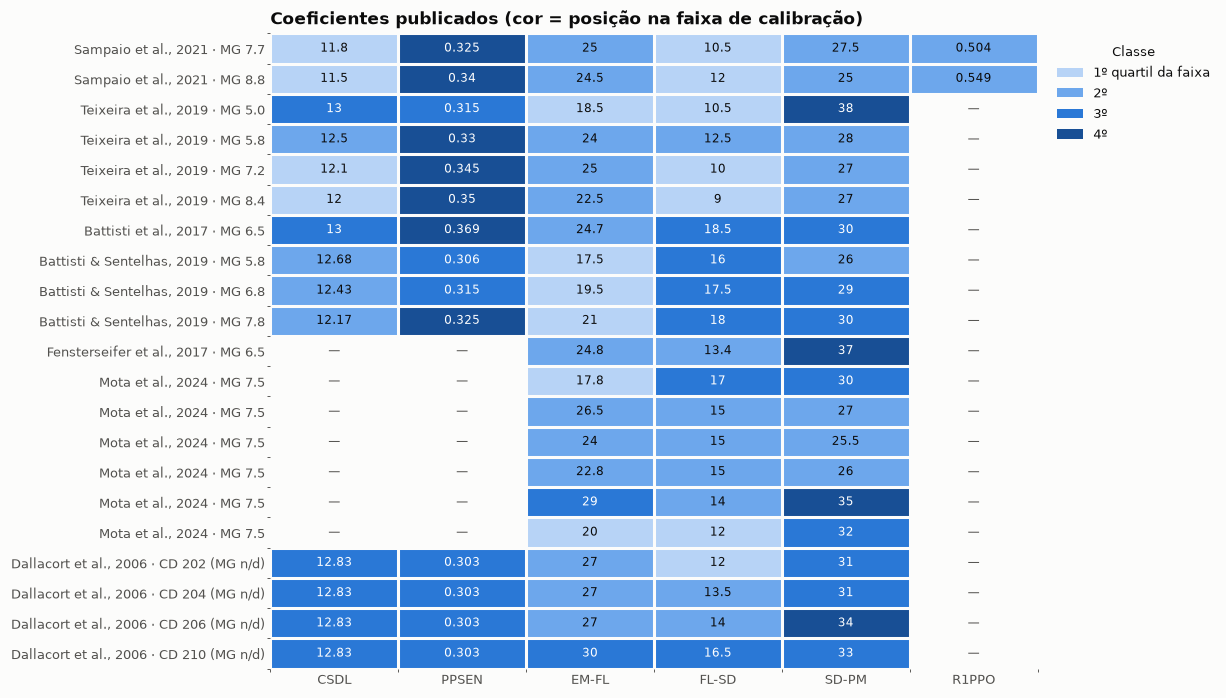

In [16]:
import calibrar_fenologia as cf
lit = pd.read_csv(RAIZ / "dados/literatura/coeficientes_literatura.csv")
cols = {"CSDL": "csdl", "PPSEN": "ppsen", "EM-FL": "em-fl", "FL-SD": "fl-sd", "SD-PM": "sd-pm", "R1PPO": "r1ppo"}
lit["rotulo"] = (lit.fonte.str.replace(r" \(.*", "", regex=True).str.slice(0, 26) + " · " +
                 np.where(lit.MG.notna(), "MG " + lit.MG.astype(str), lit.cultivar.astype(str).str.slice(0, 16) + " (MG n/d)"))
V = lit[list(cols)].values.astype(float)
P = np.array([(V[:, j] - cf.FAIXAS[k][0]) / (cf.FAIXAS[k][1] - cf.FAIXAS[k][0]) for j, k in enumerate(cols.values())]).T
fig, ax = plt.subplots(figsize=(9, 7.5))
fg.heatmap_classes(ax, P, lit.rotulo, list(cols), [-0.01, 0.25, 0.5, 0.75, 1.01], ["1º quartil da faixa", "2º", "3º", "4º"],
                   [SEQ[1], SEQ[4], SEQ[7], SEQ[10]], textos=[[f"{v:g}" for v in linha] for linha in V])
ax.set_title("Coeficientes publicados (cor = posição na faixa de calibração)")
fg.salvar(fig, "5_3_coeficientes_literatura")

## 6 Sensibilidade

**Figura 6.1 — Sensibilidade de Morris (μ* normalizado, média dos ambientes).** Classes: alta ≥ 0,5; média 0,2–0,5;
baixa 0,05–0,2; desprezível < 0,05. Justifica os 10 coeficientes calibrados e o descarte dos demais.

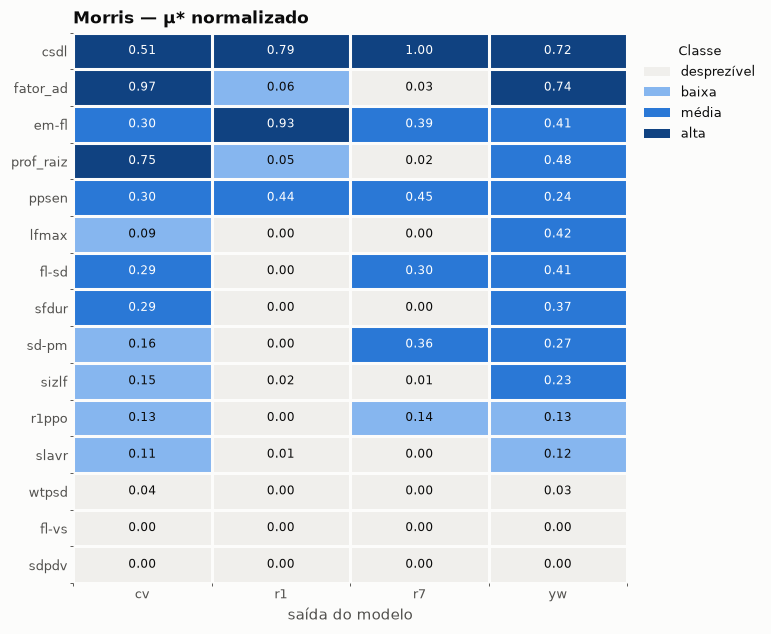

In [17]:
mo = pd.read_csv(RAIZ / "resultados/morris/indices_morris.csv")
M = mo.groupby(["parametro", "saida"]).mu_norm.mean().unstack()
M = M.loc[M.max(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(6.5, 6.5))
fg.heatmap_classes(ax, M.values, M.index, M.columns, [0, 0.05, 0.2, 0.5, 1.01], ["desprezível", "baixa", "média", "alta"],
                   [fg.CINZA_MEIO, SEQ[3], SEQ[7], SEQ[11]], fmt="{:.2f}")
ax.set_title("Morris — μ* normalizado"); ax.set_xlabel("saída do modelo")
fg.salvar(fig, "6_1_morris")

## 7 Replicação de Battisti & Sentelhas (2019)

**Figura 7.1 — Diferença entre a replicação e o artigo original, por zona.** Classes: ótimo |dif| ≤ 5%; bom ≤ 10%;
regular ≤ 20%; ruim > 20%. Valida a cadeia clima → solo → modelo antes da calibração.

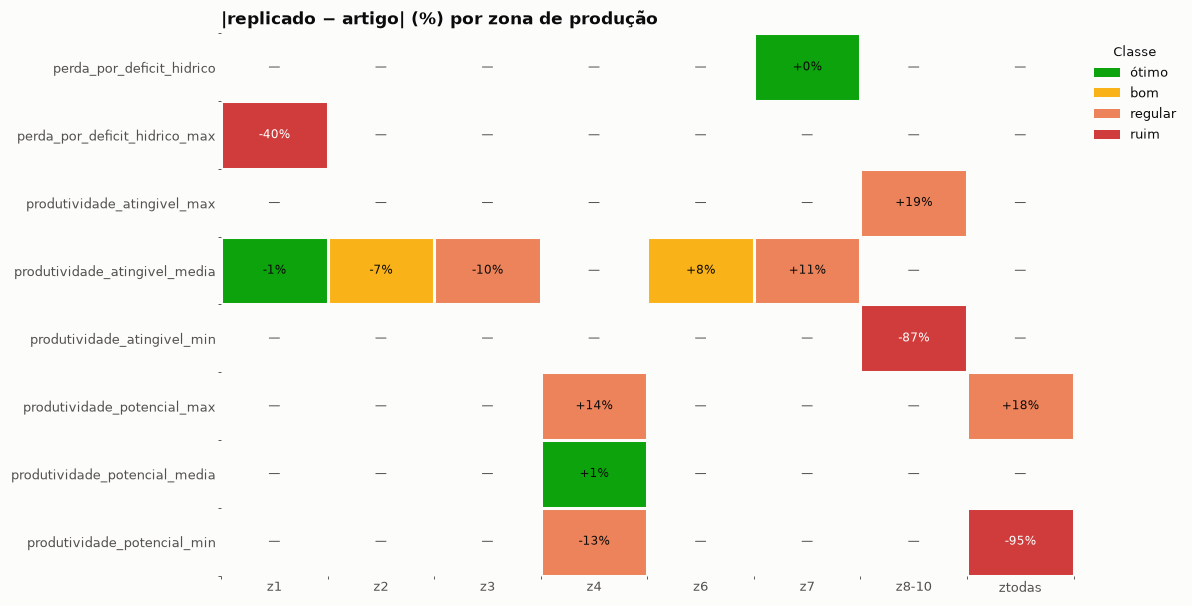

In [18]:
bs = pd.read_csv(RAIZ / "resultados/bs2019/comparacao_alvos.csv")
M = bs.pivot_table(index="variavel", columns="zona", values="dif_pct")
fig, ax = plt.subplots(figsize=(10, 0.6 * len(M) + 1.6))
fg.heatmap_classes(ax, np.abs(M.values), M.index, [f"z{c}" for c in M.columns], [0, 5, 10, 20, 1e9],
                   ["ótimo", "bom", "regular", "ruim"], [ST["bom"], ST["atenção"], ST["sério"], ST["crítico"]],
                   textos=[[f"{v:+.0f}%" for v in linha] for linha in M.values])
ax.set_title("|replicado − artigo| (%) por zona de produção")
fg.salvar(fig, "7_1_replicacao_bs2019")

## 8 Emulador

**Figura 8.1 — Emulador × DSSAT em locais fora do treino.** Densidade de pontos (validação cruzada deixando locais
inteiros de fora, ~2,8 milhões de safras). O emulador reproduz R1 e R7 com erro de ~1–2 dias, o que permite
substituir o DSSAT na MCMC.

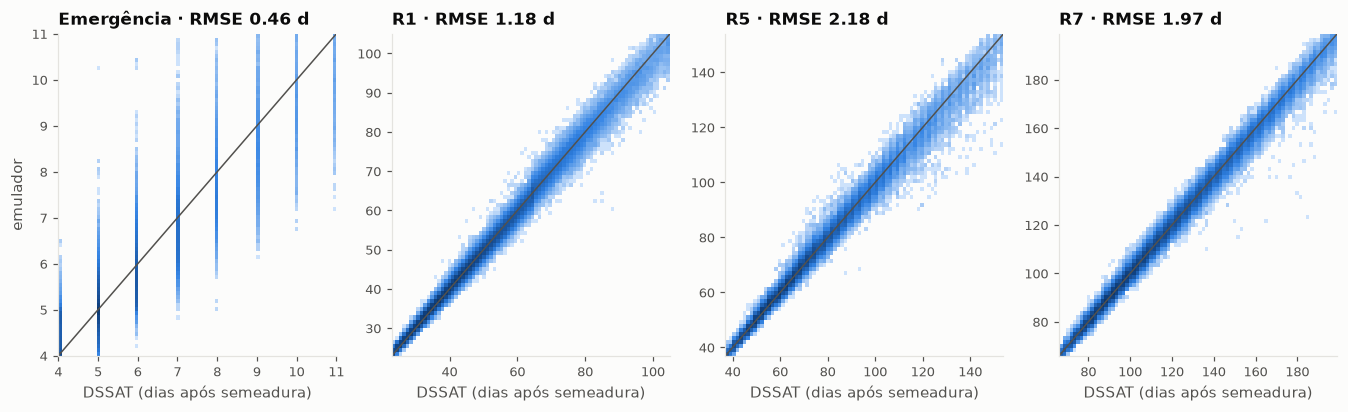

In [19]:
vp = pd.read_parquet(DE / "validacao_predicoes.parquet").sample(400_000, random_state=1)
fig, axs = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, s, nome in zip(axs, ["e", "r1", "r5", "r7"], ["Emergência", "R1", "R5", "R7"]):
    d = vp[[s, s + "_pred"]].dropna(); lo, hi = np.percentile(d[s], [0.5, 99.5])
    h = ax.hist2d(d[s], d[s + "_pred"], bins=80, range=[[lo, hi], [lo, hi]], cmap=fg.CMAP_SEQ, norm=mpl.colors.LogNorm(), cmin=1)
    ax.plot([lo, hi], [lo, hi], color=fg.TEXTO_2, lw=1)
    rmse = np.sqrt(((d[s] - d[s + "_pred"]) ** 2).mean())
    ax.set_title(f"{nome} · RMSE {rmse:.2f} d"); ax.set_xlabel("DSSAT (dias após semeadura)"); ax.grid(False)
axs[0].set_ylabel("emulador")
fg.salvar(fig, "8_1_emulador_validacao")

**Figura 8.2 — Erro do emulador por versão do treino.** RMSE (dias) com locais fora do treino. Classes: ótimo ≤ 1 d;
bom ≤ 2 d; regular ≤ 3 d; ruim > 3 d. Cada lote novo (faixas ampliadas, locais novos, R5, R1PPO) manteve ou melhorou
a acurácia.

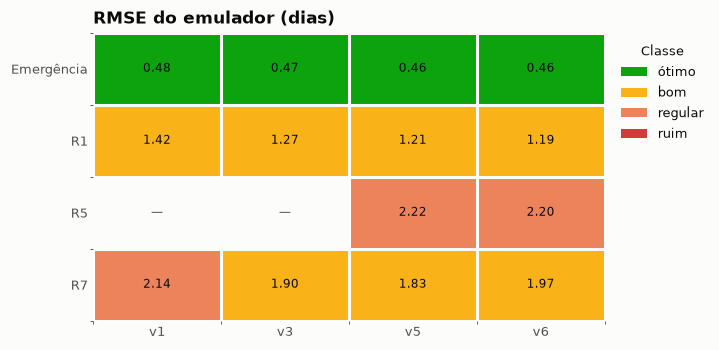

In [20]:
ver = {"v1": DE / "v1/validacao_metricas.csv", "v3": DE / "v3/validacao_metricas.csv", "v5": DE / "v5/validacao_metricas.csv", "v6": DE / "validacao_metricas.csv"}
M = pd.DataFrame({k: pd.read_csv(v).set_index("saida").rmse for k, v in ver.items()}).reindex(["e", "r1", "r5", "r7"])
fig, ax = plt.subplots(figsize=(6, 3.4))
fg.heatmap_classes(ax, M.values, ["Emergência", "R1", "R5", "R7"], M.columns, [0, 1, 2, 3, 1e9], ["ótimo", "bom", "regular", "ruim"],
                   [ST["bom"], ST["atenção"], ST["sério"], ST["crítico"]], fmt="{:.2f}")
ax.set_title("RMSE do emulador (dias)")
fg.salvar(fig, "8_2_emulador_versoes")

## 9 Calibração bayesiana

In [21]:
def cadeia(nome):
    f = DE / nome
    return emcee.backends.HDFBackend(str(f), read_only=True) if f.exists() else None
VERS = {"v3b": ("v3b_exploratoria/cadeia_v3b_a.h5", "v3b_exploratoria/cadeia_v3b_b.h5"), "v3c": ("cadeia_v3c_a.h5", "cadeia_v3c_b.h5"),
        "v5": ("cadeia_v5_a.h5", "cadeia_v5_b.h5"), "v6": ("cadeia_v6_a.h5", "cadeia_v6_b.h5"), "v7": ("cadeia_v7_a.h5", "cadeia_v7_b.h5"),
        "v8": ("cadeia_v8_a.h5", "cadeia_v8_b.h5"), "v9": ("v9_parcial/cadeia_v9_a.h5", "v9_parcial/cadeia_v9_b.h5"),
        "v10": ("v10_interrompida/cadeia_v10_a.h5", "v10_interrompida/cadeia_v10_b.h5"),
        "v11": ("cadeia_v11_a.h5", "cadeia_v11_b.h5"),
        "v12": ("v12_interrompida/cadeia_v12_a.h5", "v12_interrompida/cadeia_v12_b.h5"),
        "v13": ("cadeia_v13_a.h5", "cadeia_v13_b.h5")}
CH = {}
for v, (a, b) in VERS.items():
    A, B = cadeia(a), cadeia(b)
    if A is not None and B is not None and A.iteration > 200 and B.iteration > 200:
        CH[v] = (A.get_chain(), B.get_chain(), A.get_log_prob(), B.get_log_prob())
print({v: (c[0].shape[0], c[1].shape[0]) for v, c in CH.items()})
PLANEJADO = {"v3b": 1500, "v3c": 3000, "v5": 3000, "v6": 4000, "v7": 3000, "v8": 3500, "v9": 2700, "v10": 2500,
             "v11": 3000, "v12": 1400, "v13": 3000}   # v7, v9, v10 e v12 interrompidas (contam como concluídas para o R-hat; não convergiram)
CONCL = [v for v, c in CH.items() if min(c[0].shape[0], c[1].shape[0]) >= PLANEJADO[v]]
ULT = CONCL[-1]
for v in CH:
    if v not in CONCL:
        print(f"{v}: em execução ({CH[v][0].shape[0]} passos) — aparece só nos diagnósticos")
print("versão concluída mais recente (usada nos resultados):", ULT)
if ULT in ("v12", "v13"):     # faixa fisiológica desde a v12 (as faixas do emulador no cap. 8 já foram usadas)
    cf.FAIXAS.update({"fl-sd": (10.5, 22.0), "sd-pm": (25.0, 38.0)})

{'v3b': (1858, 1509), 'v3c': (3000, 3000), 'v5': (3000, 3000), 'v6': (4000, 4000), 'v7': (3045, 3205), 'v8': (3500, 3500), 'v9': (3337, 2783), 'v10': (2820, 2604), 'v11': (3000, 3000), 'v12': (1439, 1608), 'v13': (9000, 9000)}
versão concluída mais recente (usada nos resultados): v13


**Figura 9.1 — Convergência entre cadeias independentes (R-hat) por parâmetro e versão.** Classes: convergiu ≤ 1,01;
aceitável ≤ 1,1; fraco ≤ 1,3; não convergiu > 1,3. Resume a história da identificabilidade: FL-SD × δ8 só se
resolve com R5 (v5); o R1PPO entra na v6 e a v7 corrige o agrupamento do efeito aleatório.

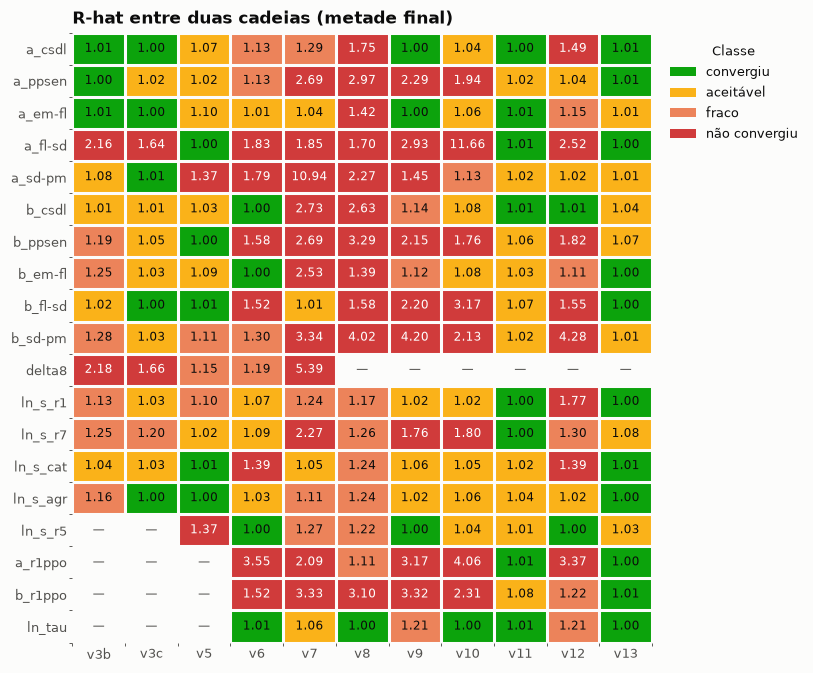

In [22]:
R = {}
for v, (a, b, *_ ) in CH.items():
    h = [a[a.shape[0] // 2:], b[b.shape[0] // 2:]]
    R[v] = {cf.NOMES[i]: fg.rhat([x[:, :, i].ravel() for x in h]) for i in range(min(a.shape[2], b.shape[2]))}
M = pd.DataFrame(R).reindex(cf.NOMES)
for v in ("v8", "v9", "v10", "v11", "v12", "v13"):
    if v in M:
        M.loc["delta8", v] = np.nan         # δ8 fixo em 11 d desde a v8
M.columns = [c if c in CONCL else f"{c} (parcial)" for c in M.columns]
fig, ax = plt.subplots(figsize=(6.8, 7.2))
fg.heatmap_classes(ax, M.values, M.index, M.columns, [0, 1.01, 1.1, 1.3, 1e9], ["convergiu", "aceitável", "fraco", "não convergiu"],
                   [ST["bom"], ST["atenção"], ST["sério"], ST["crítico"]], fmt="{:.2f}")
ax.set_title("R-hat entre duas cadeias (metade final)")
fg.salvar(fig, "9_1_rhat_versoes")

**Figura 9.2 — Trajetória do log-posterior.** Mediana entre caminhantes a cada 100 passos, duas cadeias por versão.
Cadeias que ainda sobem não atingiram o regime estacionário (ex.: v5); as duas cadeias da v6 chegam ao mesmo
patamar por regiões diferentes do espaço de parâmetros — sinal de não identificabilidade, não de falta de passos.

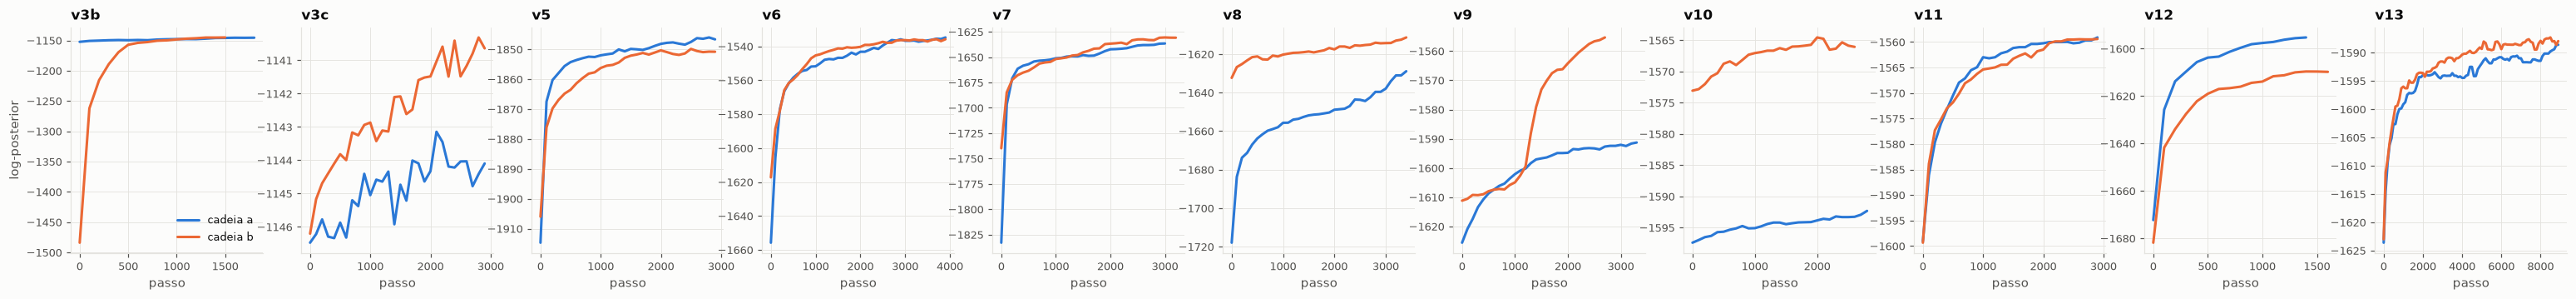

In [23]:
fig, axs = plt.subplots(1, len(CH), figsize=(3.2 * len(CH), 3.2), sharey=False)
for ax, (v, (a, b, la, lb)) in zip(np.atleast_1d(axs), CH.items()):
    for k, lp in enumerate([la, lb]):
        m = [np.median(lp[i:i + 100]) for i in range(0, len(lp), 100)]
        ax.plot(np.arange(len(m)) * 100, m, color=CAT[k], label=f"cadeia {'ab'[k]}")
    ax.set_title(v); ax.set_xlabel("passo")
np.atleast_1d(axs)[0].set_ylabel("log-posterior"); np.atleast_1d(axs)[0].legend()
fg.salvar(fig, "9_2_logpost_trajetorias")

**Figura 9.3 — A crista FL-SD × δ8 e sua resolução pelo R5.** Amostras da posterior (metade final) das duas cadeias.
Na v3c as cadeias ocupam pontos diferentes de uma crista (mesmo R8 com combinações opostas); com R5 (v5 em diante) as
duas convergem para a mesma região. Figura central da seção de identificabilidade do artigo computacional.

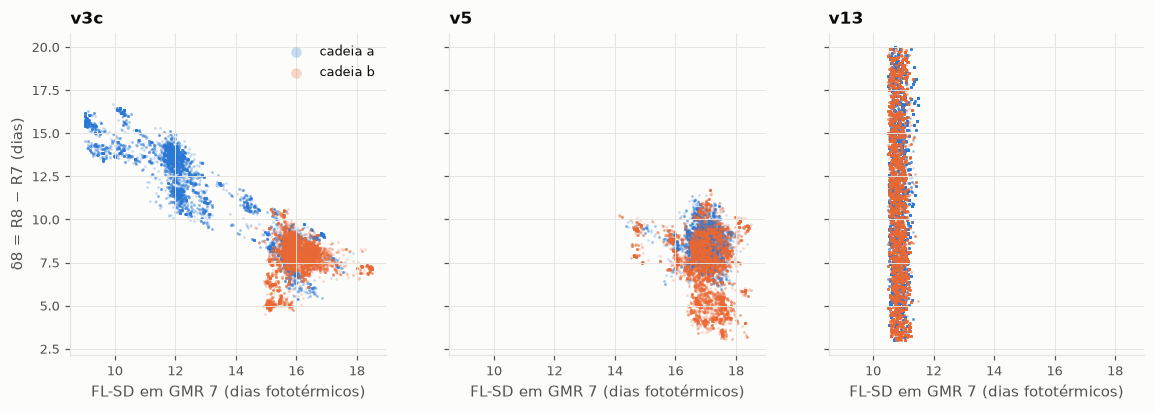

In [24]:
iF, iD = cf.NOMES.index("a_fl-sd"), cf.NOMES.index("delta8")
vs = [v for v in ["v3c", "v5", ULT] if v in CH]; vs = list(dict.fromkeys(vs))
fig, axs = plt.subplots(1, len(vs), figsize=(4.2 * len(vs), 3.8), sharex=True, sharey=True)
for ax, v in zip(np.atleast_1d(axs), vs):
    a, b = CH[v][0], CH[v][1]
    for k, c in enumerate([a, b]):
        h = c[c.shape[0] // 2:].reshape(-1, c.shape[2])[::7]
        ax.scatter(h[:, iF], h[:, iD], s=3, alpha=0.25, color=CAT[k], linewidth=0, label=f"cadeia {'ab'[k]}")
    ax.set_title(v); ax.set_xlabel("FL-SD em GMR 7 (dias fototérmicos)")
np.atleast_1d(axs)[0].set_ylabel("δ8 = R8 − R7 (dias)"); np.atleast_1d(axs)[0].legend(markerscale=4)
fg.salvar(fig, "9_3_crista_flsd_delta8")

**Figura 9.4 — Coeficientes calibrados em função do GMR (mediana e intervalo de 90%) e valores publicados.** Faixa
sombreada = incerteza posterior (cadeias da versão mais recente); pontos = calibrações da literatura. Produto
principal do artigo agronômico: cultivares genéricas brasileiras por GMR.

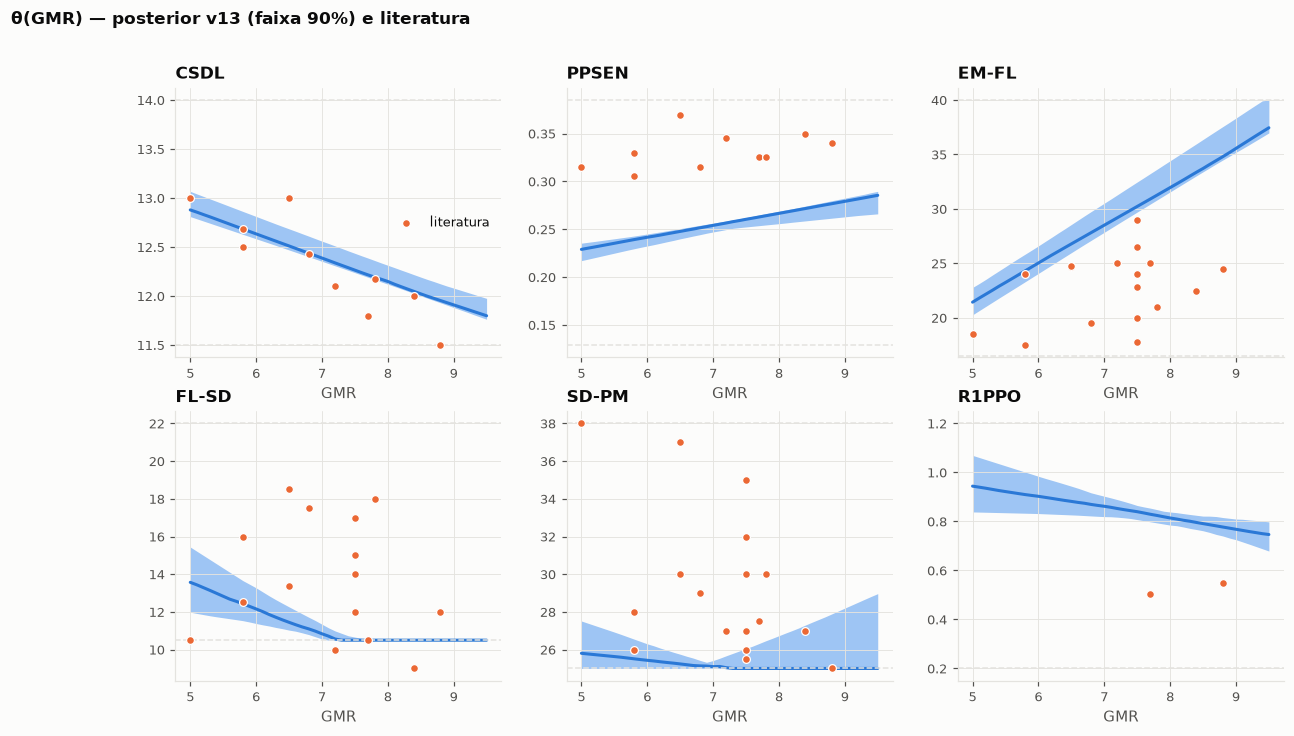

In [25]:
a, b = CH[ULT][0], CH[ULT][1]
S = np.concatenate([x[x.shape[0] // 2:].reshape(-1, x.shape[2]) for x in (a, b)])[::5]
S = np.hstack([S, np.tile([p[3] for p in cf.PARAMS[S.shape[1]:]], (len(S), 1))]) if S.shape[1] < len(cf.PARAMS) else S
ix = {n: i for i, n in enumerate(cf.NOMES)}; gg = np.linspace(5, 9.5, 46)
ks = ["csdl", "ppsen", "em-fl", "fl-sd", "sd-pm", "r1ppo"]
fig, axs = plt.subplots(2, 3, figsize=(13, 7))
for ax, k in zip(axs.ravel(), ks):
    lo, hi = cf.FAIXAS[k]
    Y = np.clip(S[:, ix[f"a_{k}"]][:, None] + S[:, ix[f"b_{k}"]][:, None] * (gg - 7), lo, hi)
    q = np.percentile(Y, [5, 50, 95], axis=0)
    ax.fill_between(gg, q[0], q[2], color=SEQ[2], linewidth=0); ax.plot(gg, q[1], color=CAT[0])
    col = {v: c for c, v in cols.items()}[k]
    ax.scatter(lit.MG, lit[col], s=26, color=CAT[1], edgecolor="white", linewidth=0.8, zorder=3, label="literatura")
    ax.axhline(lo, color=fg.GRADE, lw=1, ls="--"); ax.axhline(hi, color=fg.GRADE, lw=1, ls="--")
    ax.set_title(col); ax.set_xlabel("GMR")
axs[0, 0].legend()
fig.suptitle(f"θ(GMR) — posterior {ULT} (faixa 90%) e literatura", x=0.01, ha="left", weight="bold")
fg.salvar(fig, "9_4_theta_gmr")

In [26]:
# previsões na mediana da posterior mais recente (usadas nas figuras 9.5 e 9.6)
med = np.median(S, axis=0)
cf.DELTA8_FIXO = 11.0 if ULT in ("v8", "v9", "v10", "v11", "v12", "v13") else None     # δ8 fixo desde a v8
cf.PRIOR_LIT = ({"fl-sd": (13.9, 2.75), "sd-pm": (29.95, 3.77), "r1ppo": (0.5, 0.15)}
                if ULT in ("v10", "v11", "v12", "v13") else {})          # prior da literatura desde a v10
cal = cf.Calibracao(); pr = cal.prever(med); ob = cal.obs.copy()
ob["sim"] = [pr[e][i] for i, e in enumerate(ob.estadio)]; ob["res"] = ob.dias_ve - ob.sim
print(ob.groupby("tipo").res.describe()[["count", "mean", "std"]].round(1))

              count  mean   std
tipo                           
agregado     2656.0  -0.1   7.5
catalogo     1665.0  -3.2  10.2
experimento   453.0   8.0  11.3


**Figura 9.5 — Observado × simulado por tipo de dado.** Médias multilocais de Alliprandini (R1 e R8), experimentos
(por estádio) e catálogos. A diagonal é a concordância perfeita; o RMSE no título resume cada painel.

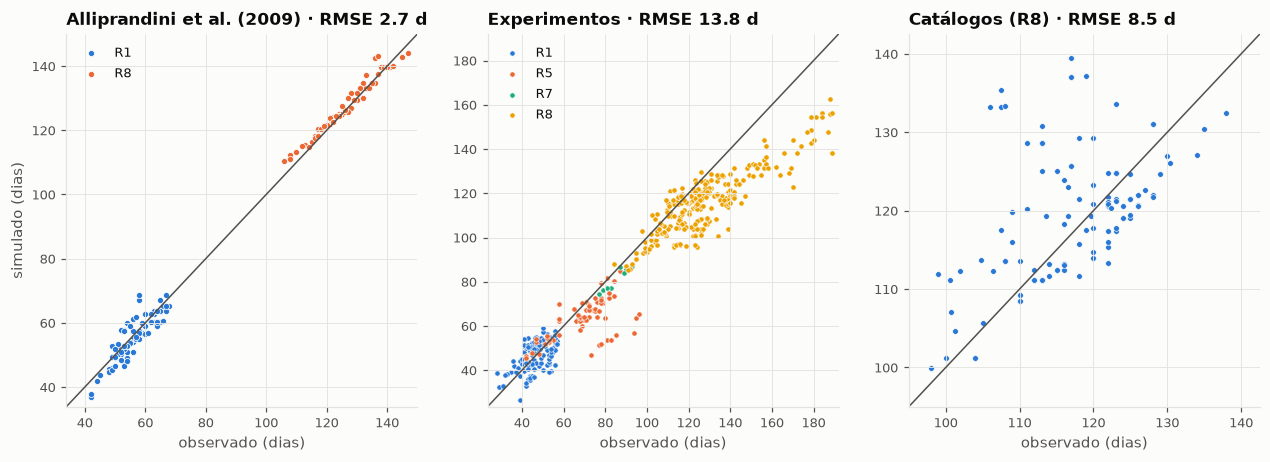

In [27]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4.4))
ag = ob[ob.tipo == "agregado"].groupby(["id_registro", "estadio"]).agg(y=("dias_ve", "first"), s=("sim", "mean")).reset_index()
for k, e in enumerate(["r1", "r8"]):
    d = ag[ag.estadio == e]; axs[0].scatter(d.y, d.s, s=16, color=CAT[k], label=e.upper(), edgecolor="white", linewidth=0.5)
ex = ob[ob.tipo == "experimento"]
for k, e in enumerate(["r1", "r5", "r7", "r8"]):
    d = ex[ex.estadio == e]; axs[1].scatter(d.dias_ve, d.sim, s=12, color=CAT[k], label=e.upper(), edgecolor="white", linewidth=0.4)
ct = ob[ob.tipo == "catalogo"].groupby("id_registro").agg(y=("dias_ve", "first"), s=("sim", "mean"))
axs[2].scatter(ct.y, ct.s, s=14, color=CAT[0], edgecolor="white", linewidth=0.4)
for ax, (t, x, y) in zip(axs, [("Alliprandini et al. (2009)", ag.y, ag.s), ("Experimentos", ex.dias_ve, ex.sim), ("Catálogos (R8)", ct.y, ct.s)]):
    lo, hi = min(x.min(), y.min()) - 3, max(x.max(), y.max()) + 3
    ax.plot([lo, hi], [lo, hi], color=fg.TEXTO_2, lw=1); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_title(f"{t} · RMSE {np.sqrt(((x - y) ** 2).mean()):.1f} d"); ax.set_xlabel("observado (dias)")
axs[0].set_ylabel("simulado (dias)"); axs[0].legend(); axs[1].legend()
fg.salvar(fig, "9_5_observado_simulado")

**Figura 9.6 — Viés por experimento, época de semeadura e estádio (observado − simulado).** Cor divergente: vermelho =
ciclo observado mais longo que o simulado. Evidencia a fraca resposta à época de semeadura (Passo Fundo em setembro,
semeaduras de outubro), que motivou calibrar o R1PPO.

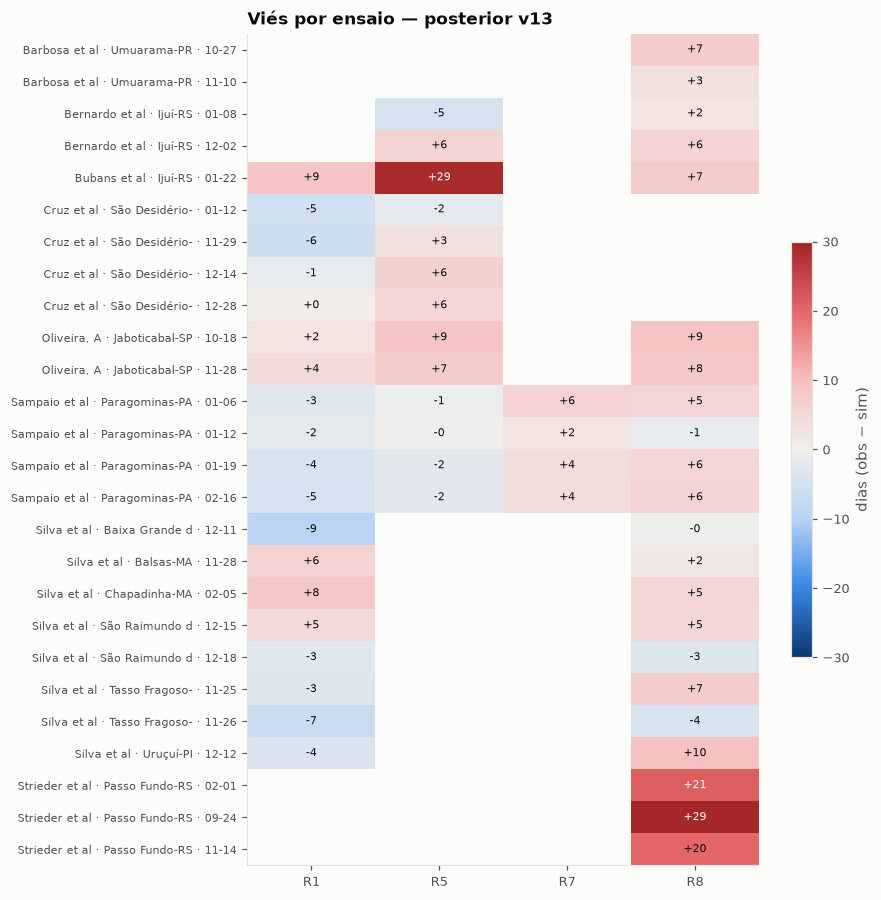

In [28]:
ex = ob[ob.tipo == "experimento"].copy()
ex["ensaio"] = ex.fonte.str.replace(r" \(.*|\..*", "", regex=True).str.slice(0, 18) + " · " + ex.local.str.slice(0, 14) + " · " + ex.data_semeadura
M = ex.pivot_table(index="ensaio", columns="estadio", values="res", aggfunc="mean").reindex(columns=["r1", "r5", "r7", "r8"])
fig, ax = plt.subplots(figsize=(7.5, 0.32 * len(M) + 1.5))
lim = 30; im = ax.imshow(M.values, cmap=fg.CMAP_DIV, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(4), ["R1", "R5", "R7", "R8"]); ax.set_yticks(range(len(M)), M.index, fontsize=7.5); ax.grid(False)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:+.0f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 20 else fg.TEXTO)
plt.colorbar(im, ax=ax, shrink=0.5, label="dias (obs − sim)"); ax.set_title(f"Viés por ensaio — posterior {ULT}")
fg.salvar(fig, "9_6_vies_ensaios")

## 10 Satélite e inferência amortizada

**Figura 10.1 — Validação da inferência amortizada em simulações não vistas.** Esquerda: GMR verdadeiro × média da
posterior. Direita: histograma dos postos do SBC (uniforme = incerteza bem calibrada). Versão final com a posterior v11
(o protótipo usava a v3b exploratória); final = v13.

SBI: final


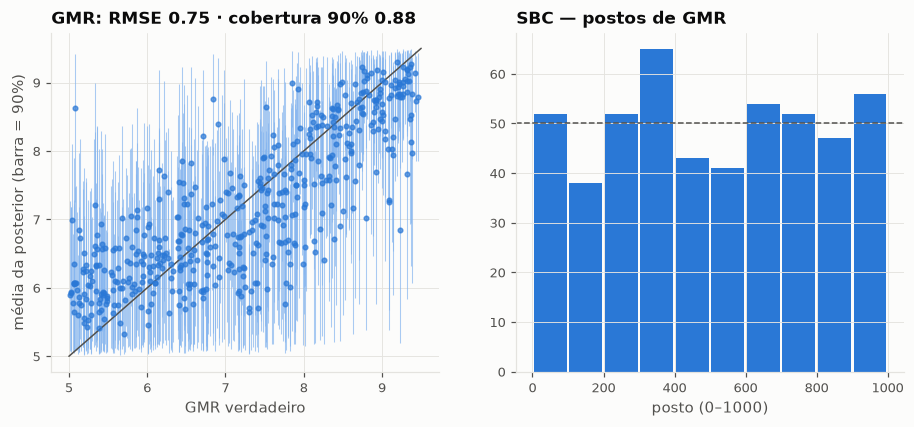

In [29]:
SBI = "final" if (RAIZ / "resultados/sbi/gmr_efetivo_final.csv").exists() else "prototipo"   # final: posterior v13
print("SBI:", SBI)
vs_ = pd.read_csv(RAIZ / f"resultados/sbi/validacao_{SBI}.csv")
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].errorbar(vs_.g_true, vs_.g_media, yerr=[vs_.g_media - vs_.g_q05, vs_.g_q95 - vs_.g_media], fmt="o", ms=3, color=CAT[0],
                ecolor=SEQ[3], elinewidth=0.7, alpha=0.7)
axs[0].plot([5, 9.5], [5, 9.5], color=fg.TEXTO_2, lw=1)
cob = ((vs_.g_q05 <= vs_.g_true) & (vs_.g_true <= vs_.g_q95)).mean()
axs[0].set_title(f"GMR: RMSE {np.sqrt(((vs_.g_media - vs_.g_true) ** 2).mean()):.2f} · cobertura 90% {cob:.2f}")
axs[0].set_xlabel("GMR verdadeiro"); axs[0].set_ylabel("média da posterior (barra = 90%)")
axs[1].hist(vs_.g_rank, bins=10, range=(0, 1000), color=CAT[0], rwidth=0.92)
axs[1].axhline(len(vs_) / 10, color=fg.TEXTO_2, ls="--", lw=1); axs[1].set_title("SBC — postos de GMR"); axs[1].set_xlabel("posto (0–1000)")
fg.salvar(fig, "10_1_sbi_validacao")

**Figura 10.2 — GMR efetivo médio (2000–2024) e tendência por década, por ponto.** Estimados do MODIS pela inferência
amortizada. O gradiente norte–sul reproduz o zoneamento de GMR sem nenhuma informação de cultivar; a tendência negativa
(azul) indica adoção de cultivares mais precoces, mais forte em MT.

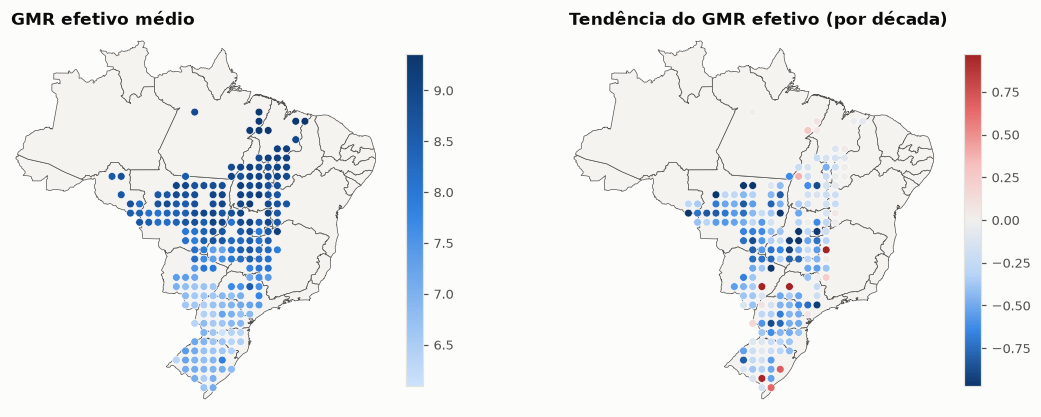

In [30]:
ge = pd.read_csv(RAIZ / f"resultados/sbi/gmr_efetivo_{SBI}.csv")
pm = ge.groupby(["lon", "lat"]).agg(g=("g_media", "mean"), n=("g_media", "size")).reset_index()
tr = ge.groupby(["lon", "lat"]).filter(lambda x: len(x) >= 8).groupby(["lon", "lat"]).apply(lambda x: 10 * np.polyfit(x.safra, x.g_media, 1)[0]).rename("tend").reset_index()
fig, axs = plt.subplots(1, 2, figsize=(12, 5.6))
fg.mapa_base(axs[0]); sc = axs[0].scatter(pm.lon, pm.lat, c=pm.g, cmap=fg.CMAP_SEQ, s=26, edgecolor="white", linewidth=0.4, zorder=3)
axs[0].set_title("GMR efetivo médio"); plt.colorbar(sc, ax=axs[0], shrink=0.7)
fg.mapa_base(axs[1]); lim = np.nanpercentile(np.abs(tr.tend), 95)
sc = axs[1].scatter(tr.lon, tr.lat, c=tr.tend, cmap=fg.CMAP_DIV, vmin=-lim, vmax=lim, s=26, edgecolor="white", linewidth=0.4, zorder=3)
axs[1].set_title("Tendência do GMR efetivo (por década)"); plt.colorbar(sc, ax=axs[1], shrink=0.7)
fg.salvar(fig, "10_2_mapa_gmr_efetivo")

**Figura 10.3 — GMR efetivo ao longo das safras por faixa de latitude.** Média dos pontos e faixa interquartil.
Pequenos múltiplos (um painel por região) para não sobrepor seis séries.

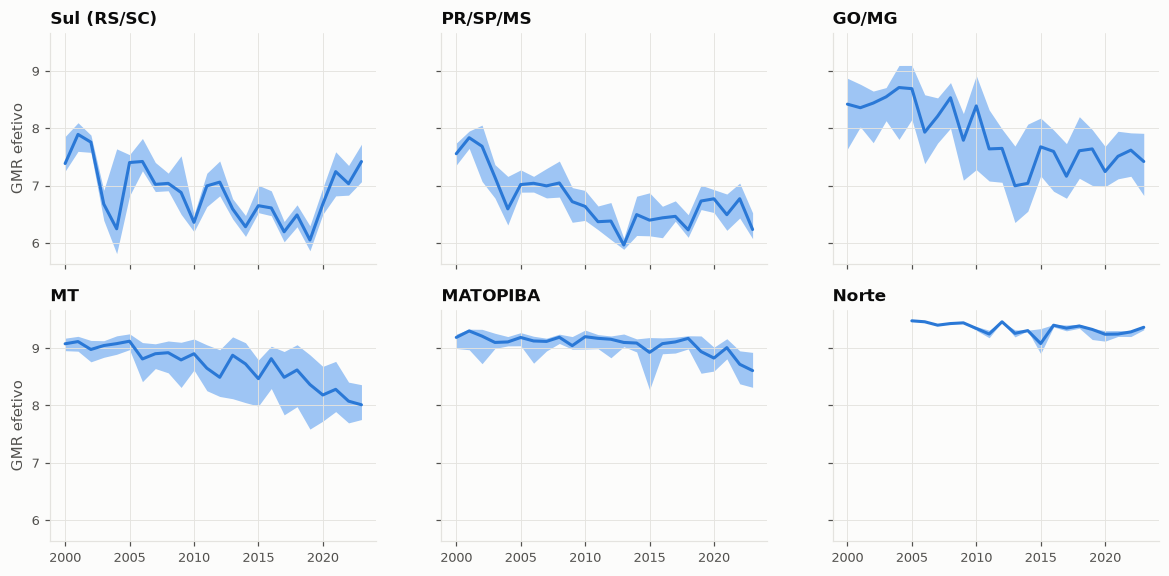

In [31]:
ge["regiao"] = ge.lat.map(reg)
fig, axs = plt.subplots(2, 3, figsize=(13, 6), sharex=True, sharey=True)
for ax, (a, b, nome) in zip(axs.ravel(), faixas):
    s = ge[ge.regiao == nome].groupby("safra").g_media
    if s.ngroups == 0:
        ax.set_title(nome); continue
    q = s.quantile([0.25, 0.5, 0.75]).unstack()
    ax.fill_between(q.index, q[0.25], q[0.75], color=SEQ[2], linewidth=0); ax.plot(q.index, q[0.5], color=CAT[0]); ax.set_title(nome)
for ax in axs[:, 0]:
    ax.set_ylabel("GMR efetivo")
fg.salvar(fig, "10_3_gmr_efetivo_series")

**Figura 10.4 — Custo computacional: MCMC por registro × inferência amortizada.** Escala logarítmica. A rede é
treinada uma vez (custo fixo) e cada inversão custa milissegundos; a MCMC repete todo o custo a cada registro.
Valores do SBI final (treino 1.348 s; 4.030 inversões em 114 s) e da MCMC por registro medida em 30 registros
(mediana de 215 s para ~1.800 amostras efetivas; CPU dividida com outras tarefas).

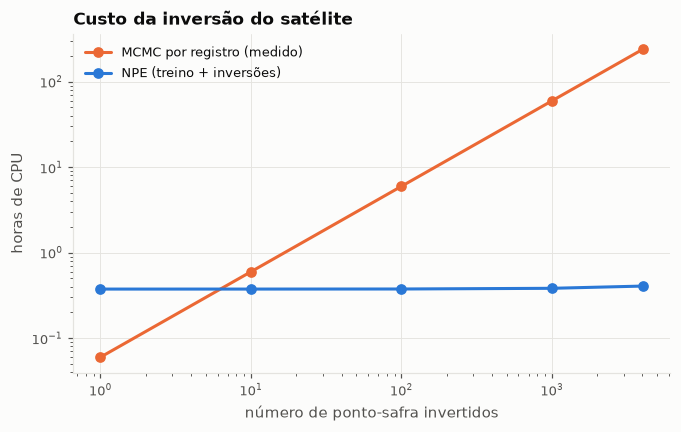

In [32]:
n = np.array([1, 10, 100, 1000, 4030])
t_npe = 1348 + 114 / 4030 * n; t_mcmc = 215.0 * n          # MCMC medida: mediana de 30 registros (mcmc_por_registro.csv)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(n, t_mcmc / 3600, color=CAT[1], marker="o", label="MCMC por registro (medido)")
ax.plot(n, t_npe / 3600, color=CAT[0], marker="o", label="NPE (treino + inversões)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("número de ponto-safra invertidos"); ax.set_ylabel("horas de CPU")
ax.set_title("Custo da inversão do satélite"); ax.legend()
fg.salvar(fig, "10_4_custo_amortizacao")

## 11 Produtividade e limitação hídrica

Opção A: crescimento da BRS 284 (Battisti & Sentelhas, 2019), fenologia θ(GMR) final e GMR efetivo e semeadura do SBI
por ponto × safra. Yp sem e Yw com limitação hídrica; 3 solos com peso pelas frações do MapBiomas. A lacuna absoluta
Yw − IBGE foi descartada (Yw < IBGE em 42% dos ponto-safra: o crescimento não tem ganho genético); o resultado é a
limitação hídrica relativa Yw/Yp, e o IBGE valida a variação entre anos.

In [33]:
PR = RAIZ / "resultados/produtividade"
lc = pd.read_csv(PR / "lacuna_pontos.csv")
lc["razao"] = (lc.yw / lc.yp).clip(upper=1)
REG = ["RS/SC", "PR/SP/MS", "GO/MG/DF/norte MS", "MT/RO/Norte", "MATOPIBA"]
print(lc.groupby("regiao")[["yp", "yw", "ibge_kg_ha", "razao"]].mean().round(2))

                        yp       yw  ibge_kg_ha  razao
regiao                                                
GO/MG/DF/norte MS  4119.34  3223.83     3061.47   0.79
MATOPIBA           4058.19  3025.77     2894.71   0.75
MT/RO/Norte        3661.18  3338.53     3134.52   0.91
PR/SP/MS           4099.71  2834.54     2983.35   0.69
RS/SC              4250.75  2075.52     2343.37   0.49


**Figura 11.1 — Limitação hídrica relativa por ponto.** Esquerda: Yw/Yp médio de 2001–2024 (1 = sem perda por água).
Direita: coeficiente de variação do Yw entre safras. O Sul combina a maior perda média com a maior instabilidade.

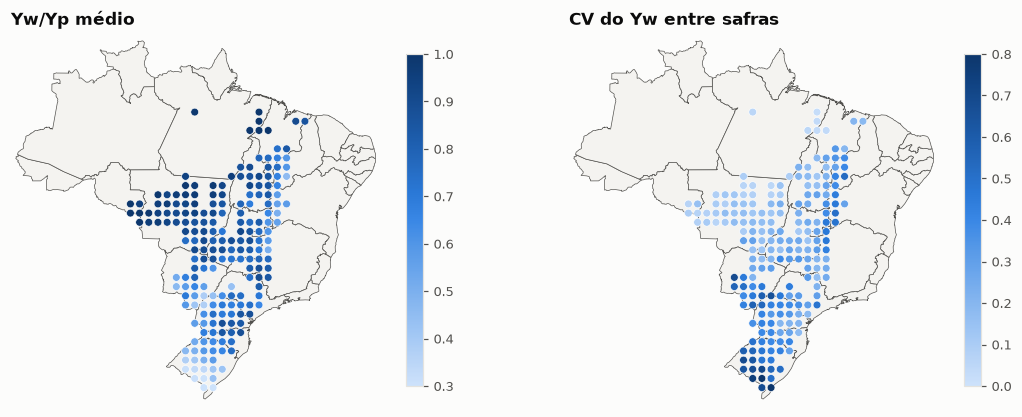

In [34]:
pm = lc.groupby(["lon", "lat"]).agg(razao=("razao", "mean"), cv=("yw", lambda x: x.std() / x.mean()), n=("yw", "size"))
pm = pm[pm.n >= 6].reset_index()
fig, axs = plt.subplots(1, 2, figsize=(12, 5.6))
fg.mapa_base(axs[0]); sc = axs[0].scatter(pm.lon, pm.lat, c=pm.razao, cmap=fg.CMAP_SEQ, vmin=0.3, vmax=1, s=26,
                                         edgecolor="white", linewidth=0.4, zorder=3)
axs[0].set_title("Yw/Yp médio"); plt.colorbar(sc, ax=axs[0], shrink=0.7)
fg.mapa_base(axs[1]); sc = axs[1].scatter(pm.lon, pm.lat, c=pm.cv, cmap=fg.CMAP_SEQ, vmin=0, vmax=0.8, s=26,
                                         edgecolor="white", linewidth=0.4, zorder=3)
axs[1].set_title("CV do Yw entre safras"); plt.colorbar(sc, ax=axs[1], shrink=0.7)
fg.salvar(fig, "11_1_mapa_limitacao_hidrica")

**Figura 11.2 — Níveis de produtividade por região: por que a lacuna absoluta foi descartada.** Médias ponderadas pela
área colhida. O IBGE sobe ~30% no período (ganho genético e de manejo); Yp e Yw simulados, com uma cultivar fixa, não.

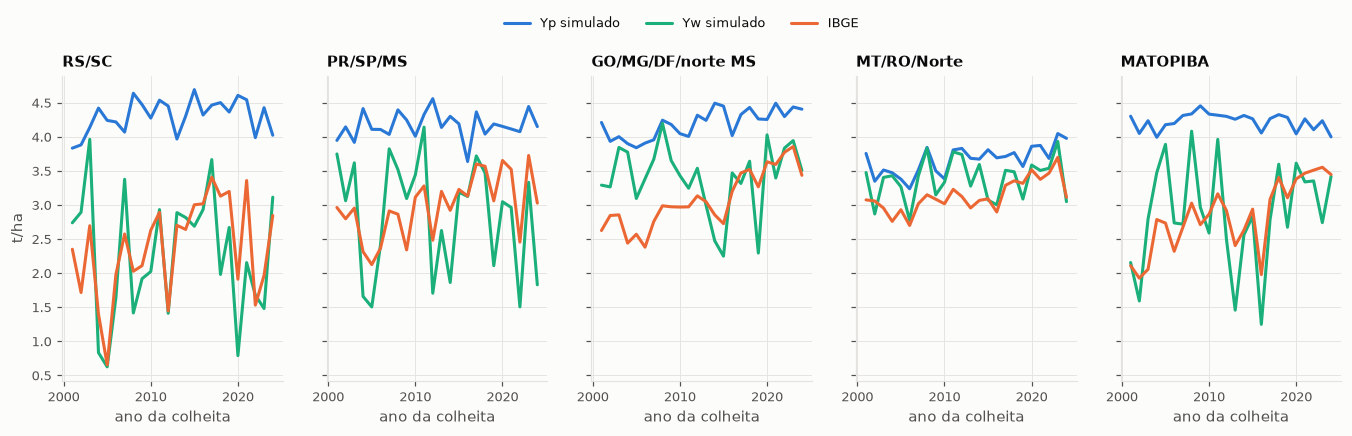

In [35]:
def media_pond(g, c):
    w = g.area_colhida_ha.fillna(g.area_colhida_ha.median())
    return np.average(g[c], weights=w)
ok = lc.dropna(subset=["ibge_kg_ha"])
fig, axs = plt.subplots(1, 5, figsize=(15, 3.6), sharey=True)
for ax, r in zip(axs, REG):
    g = ok[ok.regiao == r].groupby("ano")
    for c, cor, rot in [("yp", CAT[0], "Yp simulado"), ("yw", CAT[2], "Yw simulado"), ("ibge_kg_ha", CAT[1], "IBGE")]:
        ax.plot(g.apply(lambda x: media_pond(x, c)) / 1000, color=cor, label=rot)
    ax.set_title(r, fontsize=10); ax.set_xlabel("ano da colheita")
axs[0].set_ylabel("t/ha")
fig.legend(*axs[0].get_legend_handles_labels(), loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.06), frameon=False)
fg.salvar(fig, "11_2_niveis_produtividade")

**Figura 11.3 — Validação da variação entre anos: anomalias sem tendência do Yw simulado e do IBGE, por região.**
Anomalia = resíduo de uma reta no ano em cada célula, relativo à média da célula; média ponderada pela área. O r no
título é a correlação das duas séries (24 safras). A amplitude simulada é ~2× a do IBGE: a média municipal amortece
perdas (manejo, cultivares e semeaduras escalonadas), e a simulação usa um único GMR e uma única data por ponto-safra.

           regiao  r_ponto_safra  r_regiao_ano  n_anos
GO/MG/DF/norte MS           0.41          0.60    24.0
         MATOPIBA           0.60          0.85    24.0
      MT/RO/Norte           0.31          0.60    24.0
         PR/SP/MS           0.64          0.84    24.0
            RS/SC           0.54          0.76    24.0
           Brasil           0.55          0.76   120.0


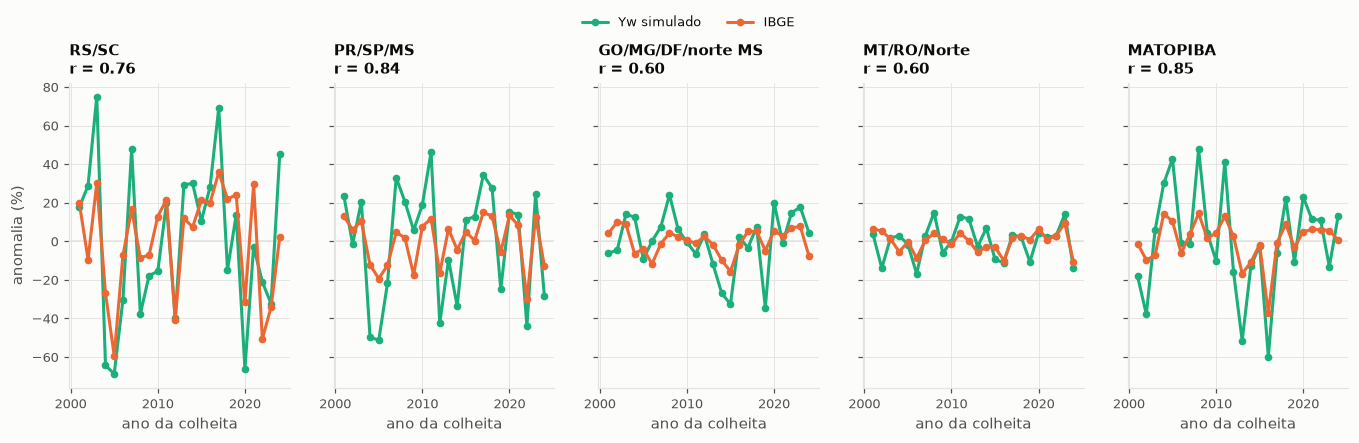

In [36]:
an = pd.read_csv(PR / "anomalias_yw_ibge.csv")
fig, axs = plt.subplots(1, 5, figsize=(15, 3.6), sharey=True)
for ax, r in zip(axs, REG):
    g = an[an.regiao == r].groupby("ano")
    yw = g.apply(lambda x: np.average(x.anom_yw, weights=x.w)); ib = g.apply(lambda x: np.average(x.anom_ibge, weights=x.w))
    ax.axhline(0, color=fg.GRADE, lw=1)
    ax.plot(100 * yw, color=CAT[2], marker="o", ms=4, label="Yw simulado")
    ax.plot(100 * ib, color=CAT[1], marker="o", ms=4, label="IBGE")
    ax.set_title(f"{r}\nr = {yw.corr(ib):.2f}", fontsize=10); ax.set_xlabel("ano da colheita")
axs[0].set_ylabel("anomalia (%)")
fig.legend(*axs[0].get_legend_handles_labels(), loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.08), frameon=False)
fg.salvar(fig, "11_3_anomalias_yw_ibge")
print(pd.read_csv(PR / "anomalias_correlacao.csv").round(2).to_string(index=False))   # tabela das correlações